# 04 - Explaining, scoring and auditing the model

**The big picture in four sentences**
1. The model from notebook 03 gives each customer a churn probability.
2. Here we ask *why*: which of a customer's features pushed their risk up?
3. We score all 7,043 customers and save one file that Power BI will read.
4. We check whether the model treats groups (gender, seniors, partners, dependents) similarly.

Nothing in this notebook changes the model. Each step says **what** it does, **why**, and **what to say if asked**.

## 1. Load the saved model and all customers
**What:** reads the saved pipeline and the full cleaned table.
**Why:** we reuse the saved model instead of retraining, so everything agrees with notebook 03.
**If asked:** *"The saved file holds the whole pipeline, so raw columns go in and a probability comes out."*

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.model_selection import StratifiedKFold, cross_val_predict

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # the project folder
sys.path.insert(0, str(ROOT / "src"))
from modeling import ADDON_COLS, FEATURES, build_pipeline, split_xy

FIGS = ROOT / "docs" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
BLUE = "#2a78d6"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e1e0d9", "axes.axisbelow": True, "font.size": 9,
                     "axes.titleweight": "bold", "axes.titlelocation": "left"})

model = joblib.load(ROOT / "models" / "churn_pipeline.joblib")                 # the saved pipeline
config = json.loads((ROOT / "models" / "model_config.json").read_text())
THRESHOLD = config["threshold"]                                                 # 0.27, chosen in notebook 03

customers = pd.read_csv(ROOT / "data" / "processed" / "telco_clean.csv")        # all 7,043 customers
X_all, y_all = split_xy(customers)
print(f"{len(customers):,} customers, offer cut-off = {THRESHOLD:.0%}")

7,043 customers, offer cut-off = 27%


/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. A fair probability for every customer (out-of-fold)
**What:** split the customers into 5 groups. Score each group with a model trained on the *other* 4 groups.
**Why:** a model scores the customers it was trained on too well, which would inflate the revenue-at-risk number.
Here no customer is ever scored by a model that has seen them.
**If asked:** *"`cross_val_predict` does the 5-way split and scoring for me."*

The saved model (trained on the training rows only) is used for the *reasons* below. The check at the end of this cell
shows the two sets of probabilities agree closely, so using both is safe.

In [2]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
churn_probability = cross_val_predict(build_pipeline(config["C"]), X_all, y_all, cv=cv, method="predict_proba")[:, 1]
customers["churn_probability"] = churn_probability.round(4)       # rounded once, here, so every later step agrees with the saved file

# Check: do these agree with the saved model's probabilities?
saved_model_probability = model.predict_proba(X_all)[:, 1]
print(f"correlation with saved model: {np.corrcoef(churn_probability, saved_model_probability)[0, 1]:.4f}")
print(f"average gap:                  {np.abs(churn_probability - saved_model_probability).mean():.4f}")
print(f"average predicted risk: {churn_probability.mean():.1%}  |  actual churn rate: {y_all.mean():.1%}")

correlation with saved model: 0.9976
average gap:                  0.0118
average predicted risk: 26.6%  |  actual churn rate: 26.5%


## 3. Why is a customer high risk? (SHAP)
**What:** SHAP starts from the *average* customer and gives every feature a push up or down. Push up = raises this
customer's churn risk compared with an average customer.
**Why:** a bare "78% risk" is hard to act on. Knowing it comes from a month-to-month contract and a short tenure is not.
**If asked:** *"For a logistic regression, a feature's push is just its weight times how far the customer is from the
average. The SHAP library does this for me, and I checked it against that formula."*

In [3]:
prep = model[:-1]                       # the preprocessing steps of the pipeline
clf = model[-1]                         # the logistic regression itself
encoded_names = prep.get_feature_names_out()

train_matrix = prep.transform(split_xy(pd.read_csv(ROOT / "data" / "processed" / "train.csv"))[0])   # defines the "average customer"
all_matrix = prep.transform(X_all)

# By default SHAP shrinks its background to 100 rows to save time; we ask it to use every training row.
masker = shap.maskers.Independent(train_matrix, max_samples=len(train_matrix))
explainer = shap.LinearExplainer(clf, masker)
shap_values = explainer.shap_values(all_matrix)          # one push per encoded column, per customer

# Check: for a linear model, SHAP = weight x (value - average value)
by_hand = clf.coef_[0] * (all_matrix - train_matrix.mean(axis=0))
print("SHAP matches the hand formula:", np.allclose(shap_values, by_hand, atol=1e-6))
print("encoded columns:", shap_values.shape[1])

SHAP matches the hand formula: True
encoded columns: 23


## 4. Combine the pushes back into the 16 original features
**What:** the model sees 23 encoded columns (for example, three separate columns for `InternetService`). People think in
the 16 original features, so we add up the pushes that belong to the same feature.
**Why:** pushes are additive, so adding them is valid. It turns "InternetService_Fiber optic = +0.5" into
"InternetService = +0.5".
**If asked:** *"One-hot encoding splits one feature into several columns; I add them back together."*

In [4]:
def parent_feature(encoded_name):
    for f in FEATURES:
        if encoded_name == f or encoded_name.startswith(f + "_"):
            return f

parents = [parent_feature(n) for n in encoded_names]
assert None not in parents, "an encoded column did not match any original feature"

pushes = pd.DataFrame(shap_values, columns=parents).T.groupby(level=0).sum().T
pushes.index = customers.index
print(pushes.shape, "= customers x original features")

(7043, 16) = customers x original features


## 5. Turn the pushes into plain-language reasons
**What:** for each customer who is at or above the offer cut-off, take the (up to) three features that push risk up the
most and write them as words using a small fixed template.
**Why:** a support agent or manager reads a sentence, not a chart.
**If asked:** *"These are template-based reason codes: simple rules, not a language model. The SHAP values decide which
features appear; the template decides the wording."*

Three small rules keep the reasons sensible:
- Customers below the cut-off just say "low risk" (their biggest push is tiny and would be misleading).
- Pushes smaller than 0.05 are ignored.
- Customers with no internet service are never told "no online security" (they cannot have it).

In [5]:
LABELS = {
    "Partner": "partner", "Dependents": "dependents", "PhoneService": "phone service",
    "MultipleLines": "multiple lines", "OnlineSecurity": "online security", "OnlineBackup": "online backup",
    "DeviceProtection": "device protection", "TechSupport": "tech support", "StreamingTV": "streaming TV",
    "StreamingMovies": "streaming movies", "PaperlessBilling": "paperless billing",
}

def describe(feature, value):
    # Turns one feature and the customer's value into a short phrase.
    if feature == "tenure":
        return f"{'new' if value <= 12 else 'fairly new'} customer ({value} month{'s' if value != 1 else ''})"
    if feature == "MonthlyCharges":
        return f"above-average monthly bill (${value:.0f})"
    if feature == "Contract":
        return f"{value.lower()} contract"
    if feature == "InternetService":
        return "no internet service" if value == "No" else f"{value.lower()} internet"
    if feature == "PaymentMethod":
        return f"pays by {value.lower()}"
    return LABELS[feature] if value == "Yes" else f"no {LABELS[feature]}"

def top_reasons(i, how_many=3):
    row = customers.loc[i]
    if row["churn_probability"] < THRESHOLD:
        return "low risk"
    reasons = []
    for feature, push in pushes.loc[i].sort_values(ascending=False).items():
        if push <= 0.05 or len(reasons) == how_many:
            break
        if feature in ADDON_COLS and row["InternetService"] == "No":
            continue                                   # no internet, so no add-ons to be "missing"
        reasons.append(describe(feature, row[feature]))
    return "; ".join(reasons) if reasons else "no notable risk factors"

customers["top_reasons"] = [top_reasons(i) for i in customers.index]

pd.set_option("display.max_colwidth", None)
p = customers["churn_probability"]
picks = [p.idxmax(), (p - 0.40).abs().idxmin(), p.idxmin()]          # highest risk, a medium-risk one, lowest risk
examples = customers.loc[picks, ["customerID", "churn_probability", "top_reasons"]]
examples.assign(churn_probability=examples["churn_probability"].map("{:.0%}".format)).set_index("customerID")

,churn_probability,top_reasons
customerID,,
4910-GMJOT,86%,new customer (1 month); month-to-month contract; fiber optic internet
8069-YQQAJ,40%,fairly new customer (14 months); month-to-month contract; no phone service
3996-ZNWYK,0%,low risk


## 6. Risk bands, revenue at risk, and the file for Power BI
**What:** adds three columns and saves everything as one table.
- **Risk band:** Low = below the offer cut-off (27%); Medium = 27% up to 50%; High = 50% or more.
- **Expected monthly revenue at risk** = churn probability x monthly charges. Only customers who are still active
  (`Churn = No`) count; customers who already left get 0.
- `risk_band_order` (1, 2, 3) lets Power BI sort Low, Medium, High correctly.

**Why:** Power BI reads this single file; no modelling happens there.
**If asked:** *"It is an expected value from calibrated probabilities, not a forecast of exactly what will be lost."*

In [6]:
customers["risk_band"] = pd.cut(customers["churn_probability"], [0, THRESHOLD, 0.50, 1.01],
                                labels=["Low", "Medium", "High"], right=False).astype(str)
customers["risk_band_order"] = customers["risk_band"].map({"Low": 1, "Medium": 2, "High": 3})
customers["is_active"] = (customers["Churn"] == "No")
customers["expected_monthly_revenue_at_risk"] = np.where(
    customers["is_active"], customers["churn_probability"] * customers["MonthlyCharges"], 0.0
).round(2)

# Sanity checks before saving
assert len(customers) == 7043 and customers["churn_probability"].between(0, 1).all()
assert customers[["risk_band", "top_reasons"]].notna().all().all()

OUT_CSV = ROOT / "data" / "processed" / "telco_predictive_scores.csv"
customers.to_csv(OUT_CSV, index=False)
print(f"Saved {OUT_CSV.relative_to(ROOT)}  ({customers.shape[0]:,} rows x {customers.shape[1]} columns)")

active = customers[customers["is_active"]]
summary = active.groupby("risk_band").agg(customers=("customerID", "count"),
                                          monthly_revenue=("MonthlyCharges", "sum"),
                                          expected_revenue_at_risk=("expected_monthly_revenue_at_risk", "sum"))
display(summary.loc[["Low", "Medium", "High"]].round(0).astype(int))
print(f"Active customers: {len(active):,}  |  their monthly revenue: ${active['MonthlyCharges'].sum():,.0f}")
print(f"Expected monthly revenue at risk: ${active['expected_monthly_revenue_at_risk'].sum():,.0f} "
      f"({active['expected_monthly_revenue_at_risk'].sum() / active['MonthlyCharges'].sum():.1%} of it)")

Saved data/processed/telco_predictive_scores.csv  (7,043 rows x 30 columns)


,customers,monthly_revenue,expected_revenue_at_risk
risk_band,,,
Low,3824,216268,19844
Medium,821,57664,21613
High,529,43054,26839


Active customers: 5,174  |  their monthly revenue: $316,986
Expected monthly revenue at risk: $68,295 (21.5% of it)


## 7. Which features matter most overall?
**What:** the average size of each feature's push (ignoring direction), across all customers.
**Why:** a one-picture summary of what the model relies on. We compare it with the EDA to see if the model agrees with the data.
**If asked:** *"It averages absolute SHAP values after combining the encoded columns."*

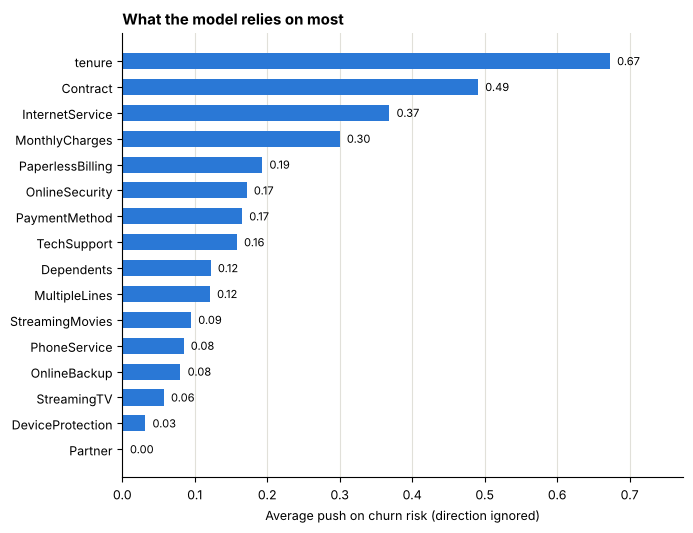

,average push
tenure,0.67
Contract,0.49
InternetService,0.37
MonthlyCharges,0.30
PaperlessBilling,0.19
OnlineSecurity,0.17


In [7]:
importance = pushes.abs().mean().sort_values()

fig, ax = plt.subplots(figsize=(7, 5.4))
ax.barh(importance.index, importance.values, color=BLUE, height=0.62)
for y, v in enumerate(importance.values):
    ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=8)
ax.set_xlim(0, importance.max() * 1.15)
ax.set_xlabel("Average push on churn risk (direction ignored)")
ax.set_title("What the model relies on most")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIGS / "explain_01_feature_importance.png", dpi=160, bbox_inches="tight")
plt.show()
importance.sort_values(ascending=False).head(6).round(2).to_frame("average push")

## 8. Does the model treat groups similarly? (fairness table)
**What:** for each group we compare how often it is flagged, how many of its real churners are caught, and how many of
its loyal customers are flagged by mistake. "Flagged" means probability at or above the cut-off (27%).
**Why:** we left `gender` and `SeniorCitizen` out of the model, but that does not guarantee similar treatment, because
other columns can stand in for them. So we measure the outcomes.
**If asked:** *"I audited the results by group instead of assuming that dropping a column makes the model fair."*

Terms: **recall** = of customers who really churned, the share we flagged. **False-positive rate** = of customers who
stayed, the share we flagged anyway (they would get an offer they did not need).

In [8]:
flagged = customers["churn_probability"] >= THRESHOLD
churned = customers["churn_flag"] == 1

groups = {
    "gender": customers["gender"],
    "SeniorCitizen": customers["SeniorCitizen"].map({0: "Non-senior", 1: "Senior"}),
    "Partner": customers["Partner"],
    "Dependents": customers["Dependents"],
}
rows = []
for dimension, column in groups.items():
    for group in sorted(column.unique()):
        m = column == group
        rows.append({
            "dimension": dimension, "group": group, "customers": int(m.sum()),
            "actual churn rate": churned[m].mean(),
            "average predicted risk": customers.loc[m, "churn_probability"].mean(),
            "flagged": flagged[m].mean(),
            "recall": (flagged & churned)[m].sum() / churned[m].sum(),
            "false-positive rate": (flagged & ~churned)[m].sum() / (~churned)[m].sum(),
        })
audit = pd.DataFrame(rows)
audit.to_csv(ROOT / "docs" / "fairness_audit.csv", index=False)

percent = {c: "{:.1%}" for c in ["actual churn rate", "average predicted risk", "flagged", "recall", "false-positive rate"]}
audit.style.format(percent).hide(axis="index")

dimension,group,customers,actual churn rate,average predicted risk,flagged,recall,false-positive rate
gender,Female,3488,26.9%,26.8%,40.5%,79.6%,26.1%
gender,Male,3555,26.2%,26.3%,39.7%,78.1%,26.1%
SeniorCitizen,Non-senior,5901,23.6%,24.2%,35.8%,75.9%,23.4%
SeniorCitizen,Senior,1142,41.7%,38.8%,62.2%,87.4%,44.1%
Partner,No,3641,33.0%,33.0%,51.1%,82.9%,35.4%
Partner,Yes,3402,19.7%,19.7%,28.3%,71.4%,17.7%
Dependents,No,4933,31.3%,31.2%,48.2%,81.8%,32.9%
Dependents,Yes,2110,15.5%,15.6%,21.0%,64.7%,13.1%


## 9. What we see

**Reasons and importance**
- The model leans most on **tenure, Contract, InternetService and MonthlyCharges** (average pushes 0.67, 0.49, 0.37, 0.30),
  which agrees with the EDA. Add-on columns such as online security and tech support rank lower here than in the EDA because
  their effect overlaps with `InternetService` (customers with no internet have none of them).
- For high-risk customers the reasons are mostly the same trio: a new customer, a month-to-month contract, and fibre internet.

**Revenue at risk (active customers only)**

| Risk band | Active customers | Their monthly revenue | Expected monthly revenue at risk |
|---|---|---|---|
| Low | 3,824 | $216,268 | $19,844 |
| Medium | 821 | $57,664 | $21,613 |
| High | 529 | $43,054 | $26,839 |

- Total expected monthly revenue at risk is **$68,295, which is 21.5% of the $316,986** that active customers pay.
- The 529 High-risk customers are 10% of active customers and 14% of the revenue, but hold
  **39% of the expected revenue at risk**. Medium plus High (1,350 customers, 26%) hold 71%.
  This is the case for focusing retention effort.
- **How to read the 21.5%:** it is an exposure score, not a forecast. The data has no time window, so the number
  says "this much revenue sits with customers who resemble past churners", not "we will lose this much next quarter".

**Fairness table** (out-of-fold predictions for all customers; flagged = probability 0.27 or higher)

| Group | Churn rate | Flagged | Recall | False-positive rate |
|---|---|---|---|---|
| Female / Male | 26.9% / 26.2% | 40.5% / 39.7% | 79.6% / 78.1% | 26.1% / 26.1% |
| Non-senior / Senior | 23.6% / 41.7% | 35.8% / 62.2% | 75.9% / 87.4% | 23.4% / 44.1% |
| Partner: no / yes | 33.0% / 19.7% | 51.1% / 28.3% | 82.9% / 71.4% | 35.4% / 17.7% |
| Dependents: no / yes | 31.3% / 15.5% | 48.2% / 21.0% | 81.8% / 64.7% | 32.9% / 13.1% |

- **Gender:** nearly identical on every measure. The differences are within noise.
- **Seniors:** flagged far more often (62% vs 36%) and, among customers who stayed, nearly twice as likely to be flagged by mistake
  (44% vs 23%). We left `SeniorCitizen` out of the model, but other columns stand in for it. The model also slightly
  under-predicts senior churn (38.8% predicted vs 41.7% actual). A wrong flag here means an unneeded discount, so the harm is mostly cost, not denial.
- **Partner and dependents:** the model catches fewer real churners among customers who have them (recall 71% and 65%, against 83% and 82%).
  Those customers are less likely to receive an offer they would have needed.
- **Why this happens:** the groups have different true churn rates, and one cut-off cannot equalise every error rate at once.
  That tension is exactly what Project 3 (training with a fairness constraint) addresses.
- Groups range from about 1,100 to 5,900 customers, so differences of two to three points are noise.

**Limits**
- Reasons describe what the *model* uses; "month-to-month contract" is a risk marker, not proof that the contract causes churn.
- `Partner` and `Dependents` are model inputs, but none of the 2,823 customers at or above the cut-off has them among their
  top three reasons, so they never appear in the text an agent would read. If that changed with new data, hiding them from
  the reason text would be sensible: an agent cannot change them, and they invite stereotyping.

## 10. Questions you may be asked

**Why did you score customers "out-of-fold"?** A model scores the customers it trained on too well. With 5-fold scoring, no
customer is scored by a model that saw them, so the revenue-at-risk number is not inflated.

**What is SHAP in one sentence?** It splits one customer's risk into pushes from each feature, starting from the average customer.
For logistic regression each push is just the weight times how far the customer is from average, and I checked the library
against that formula.

**Why add the encoded columns together?** One-hot encoding splits one feature (like `InternetService`) into several columns.
SHAP pushes are additive, so summing them gives the push of the original feature.

**Are the reasons written by AI?** No. SHAP decides which features appear, and a small fixed template turns them into words.

**You dropped `gender`; why audit it?** Dropping a column does not guarantee similar treatment, because other columns can stand
in for it. Auditing the outcomes by group shows what actually happens.

**What is "expected monthly revenue at risk", and is it a forecast?** Churn probability times monthly charges, for customers who
are still active. It is an exposure score. The data has no time window, so it is not a prediction of next quarter's losses.

**Where do the risk bands come from?** Low is below the 27% offer cut-off (from the cost rule in notebook 03), High is 50% or more
(more likely to leave than stay), and Medium is in between.